# Лабораторная работа №2 — Классификация пассажиров Titanic

**Цель:** предсказать `Survived` (1 — выжил, 0 — не выжил). Выполнить EDA, честную предобработку, baseline, пять моделей, метрики, важность признаков и анализ ошибок.

**Данные:** Titanic Dataset (891 пассажир). Источник задания: [Kaggle](https://www.kaggle.com/datasets/yasserh/titanic-dataset); открытая копия CSV: [GitHub](https://github.com/datasciencedojo/datasets/blob/master/titanic.csv). Файл `titanic.csv` также приложен. **Выполняйте ячейки сверху вниз.**

Важно: тест используется **только для окончательного сравнения**, подбор гиперпараметров производится по кросс-валидации на обучающей выборке. Если у всей группы зафиксировано другое разбиение, нужно заменить `TEST_SIZE` и `RANDOM_STATE` на значения преподавателя.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
TEST_SIZE = 0.20
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)


## 1. Загрузка и первичный анализ

Сначала пробуем загрузить CSV **онлайн**. Если сеть недоступна, используем приложенный `titanic.csv`. Обе версии содержат одинаковый стандартный набор Titanic из 891 записи.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
try:
    df = pd.read_csv(DATA_URL)
    print('Загружено онлайн:', DATA_URL)
except Exception as exc:
    print(f'Онлайн-источник недоступен ({type(exc).__name__}). Используется локальный CSV.')
    candidates = [Path('titanic.csv'), Path('/mnt/data/titanic.csv')]
    local = next((p for p in candidates if p.exists()), None)
    if local is None:
        raise FileNotFoundError('Положите titanic.csv рядом с ноутбуком') from exc
    df = pd.read_csv(local)

assert df.shape == (891, 12), f'Неожиданная форма данных: {df.shape}'
assert set(df['Survived'].dropna().unique()) == {0, 1}
print('Размер:', df.shape)
display(df.head())


Загружено онлайн: https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv
Размер: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print('Типы столбцов:')
display(df.dtypes.rename('dtype').to_frame())
print('Пропуски:')
display(pd.DataFrame({'missing': df.isna().sum(), 'missing_%': (100*df.isna().mean()).round(2)}))
print('Полных дубликатов:', df.duplicated().sum())
print('Дубликатов PassengerId:', df['PassengerId'].duplicated().sum())
print('Распределение классов:')
display(pd.DataFrame({'count': df.Survived.value_counts().sort_index(),
                      'percent': (df.Survived.value_counts(normalize=True).sort_index()*100).round(1)}))
display(df.describe(include='all').T)


Типы столбцов:


,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


Пропуски:


,missing,missing_%
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


Полных дубликатов: 0
Дубликатов PassengerId: 0
Распределение классов:


,count,percent
Survived,,
0,549,61.6
1,342,38.4


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,1601,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


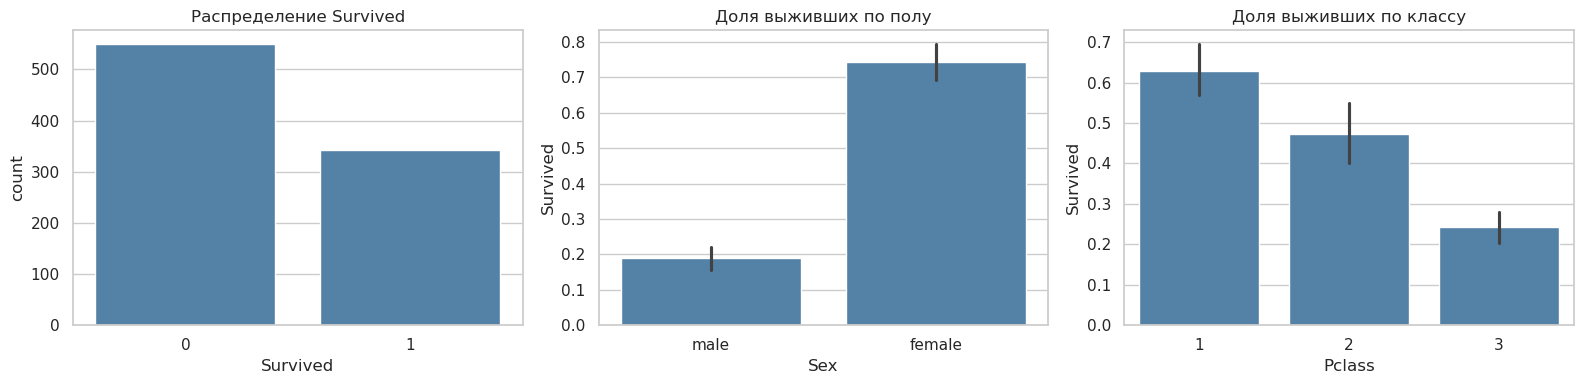

Доля выживших по полу и классу:


mean  count
Sex    Pclass              
female 1       0.968     94
       2       0.921     76
       3       0.500    144
male   1       0.369    122
       2       0.157    108
       3       0.135    347

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
sns.countplot(data=df, x='Survived', color='steelblue', ax=axes[0]); axes[0].set_title('Распределение Survived')
sns.barplot(data=df, x='Sex', y='Survived', color='steelblue', ax=axes[1]); axes[1].set_title('Доля выживших по полу')
sns.barplot(data=df, x='Pclass', y='Survived', color='steelblue', ax=axes[2]); axes[2].set_title('Доля выживших по классу')
plt.tight_layout(); plt.show()
print('Доля выживших по полу и классу:')
display(df.groupby(['Sex','Pclass'])['Survived'].agg(['mean','count']).round(3))


**Промежуточный вывод.** Целевая переменная несбалансирована: погибших больше, чем выживших, поэтому одной Accuracy недостаточно. Пол и класс билета связаны с вероятностью выживания (корреляция не доказывает причинность). Пропуски `Age`, `Cabin`, `Embarked` требуют обработки. `PassengerId` является идентификатором; `Name`, `Ticket`, `Cabin` могут позволить запоминать конкретных пассажиров или группы. Для честной базовой постановки **исключаем эти четыре столбца**; `Cabin` также имеет много пропусков.

## 2. Подготовка и единое разбиение

`Pclass` рассматривается как категория, даже если записан числом. Медиана заполняет пропуски в числовых полях, наиболее частая категория — в категориальных. One-Hot Encoding превращает категории в числовые признаки. Эти операции **внутри Pipeline** и обучаются только на соответствующих тренировочных данных. Для SVM и KNN добавляется StandardScaler: эти алгоритмы чувствительны к масштабу; деревьям масштабирование не нужно.

In [5]:
feature_cols = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X = df[feature_cols].copy()
X['Pclass'] = X['Pclass'].astype(str)
y = df['Survived'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Доля Survived=1 — train:', round(y_train.mean(),3), 'test:', round(y_test.mean(),3))

numeric_features = ['Age','SibSp','Parch','Fare']
categorical_features = ['Pclass','Sex','Embarked']

def preprocessing(scale=False):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        numeric_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer(transformers=[
        ('num', Pipeline(numeric_steps), numeric_features),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


Train: (712, 7) Test: (179, 7)
Доля Survived=1 — train: 0.383 test: 0.385


## 3. Dummy baseline и подбор пяти моделей

Основной критерий: **F1 для класса 1**, целевой порог **строго больше 0.70**. `GridSearchCV` подбирает параметры только по тренировочным фолдам; тест на этом этапе не используется. Dummy предсказывает наиболее частый класс.

In [6]:
search_spaces = {
    'Decision Tree': (DecisionTreeClassifier(random_state=RANDOM_STATE), False,
                      {'model__max_depth': [3, 5, 8, None], 'model__min_samples_leaf': [1, 3, 6]}),
    'Random Forest': (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), False,
                      {'model__n_estimators': [150], 'model__max_depth': [4, 7, None],
                       'model__min_samples_leaf': [1, 3]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE), False,
                          {'model__n_estimators': [75, 150], 'model__learning_rate': [0.05, 0.1],
                           'model__max_depth': [2, 3]}),
    'SVM': (SVC(), True, {'model__C': [0.5, 1, 5], 'model__kernel': ['rbf'],
                         'model__gamma': ['scale', 0.1]}),
    'KNN': (KNeighborsClassifier(), True, {'model__n_neighbors': [5, 9, 15],
                                           'model__weights': ['uniform','distance']})
}

models = {'Dummy baseline': Pipeline([('prep', preprocessing()),
                                     ('model', DummyClassifier(strategy='most_frequent'))])}
models['Dummy baseline'].fit(X_train, y_train)
cv_f1 = {'Dummy baseline': 0.0}  # Всегда предсказывает 0, значит F1 для класса 1 = 0.

for name, (estimator, scale, params) in search_spaces.items():
    pipe = Pipeline([('prep', preprocessing(scale=scale)), ('model', estimator)])
    search = GridSearchCV(pipe, params, scoring='f1', cv=cv, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    models[name] = search.best_estimator_
    cv_f1[name] = search.best_score_
    print(f'{name:20s} CV F1={search.best_score_:.3f}; параметры={search.best_params_}')

print('\nМодель выбрана по TRAIN CV (не по TEST).')
best_name = max((n for n in models if n != 'Dummy baseline'), key=lambda n: cv_f1[n])
print('Лучшая по CV:', best_name)


Decision Tree        CV F1=0.731; параметры={'model__max_depth': None, 'model__min_samples_leaf': 3}
Random Forest        CV F1=0.737; параметры={'model__max_depth': 4, 'model__min_samples_leaf': 1, 'model__n_estimators': 150}
Gradient Boosting    CV F1=0.767; параметры={'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 150}
SVM                  CV F1=0.754; параметры={'model__C': 1, 'model__gamma': 0.1, 'model__kernel': 'rbf'}
KNN                  CV F1=0.740; параметры={'model__n_neighbors': 15, 'model__weights': 'uniform'}

Модель выбрана по TRAIN CV (не по TEST).
Лучшая по CV: Gradient Boosting


## 4. Финальные метрики на отложенном тесте

Все шесть моделей проверяются **один раз** на одном и том же тестовом наборе. Лидер по test F1 показывается только для сравнения и **не используется для нового подбора**.

In [7]:
rows = []
all_predictions = {}
for name, pipe in models.items():
    pred = pipe.predict(X_test)
    all_predictions[name] = pred
    rows.append({'Модель': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred, zero_division=0),
                 'Recall': recall_score(y_test, pred, zero_division=0),
                 'F1': f1_score(y_test, pred, zero_division=0),
                 'F1 CV (train)': cv_f1[name],
                 'F1 > 0.70': f1_score(y_test, pred, zero_division=0) > 0.70})
leaderboard = pd.DataFrame(rows).sort_values('F1', ascending=False).reset_index(drop=True)
display(leaderboard.style.format({c:'{:.3f}' for c in ['Accuracy','Precision','Recall','F1','F1 CV (train)']}))
print('Модель с наибольшим F1 на тесте (описательно):', leaderboard.loc[0,'Модель'])
print('Окончательно выбранная до просмотра теста (по CV):', best_name)


,Модель,Accuracy,Precision,Recall,F1,F1 CV (train),F1 > 0.70
0,SVM,0.821,0.803,0.710,0.754,0.754,True
1,KNN,0.804,0.793,0.667,0.724,0.740,True
2,Gradient Boosting,0.804,0.804,0.652,0.720,0.767,True
3,Decision Tree,0.771,0.689,0.739,0.713,0.731,True
4,Random Forest,0.793,0.833,0.580,0.684,0.737,False
5,Dummy baseline,0.615,0.000,0.000,0.000,0.000,False


Модель с наибольшим F1 на тесте (описательно): SVM
Окончательно выбранная до просмотра теста (по CV): Gradient Boosting


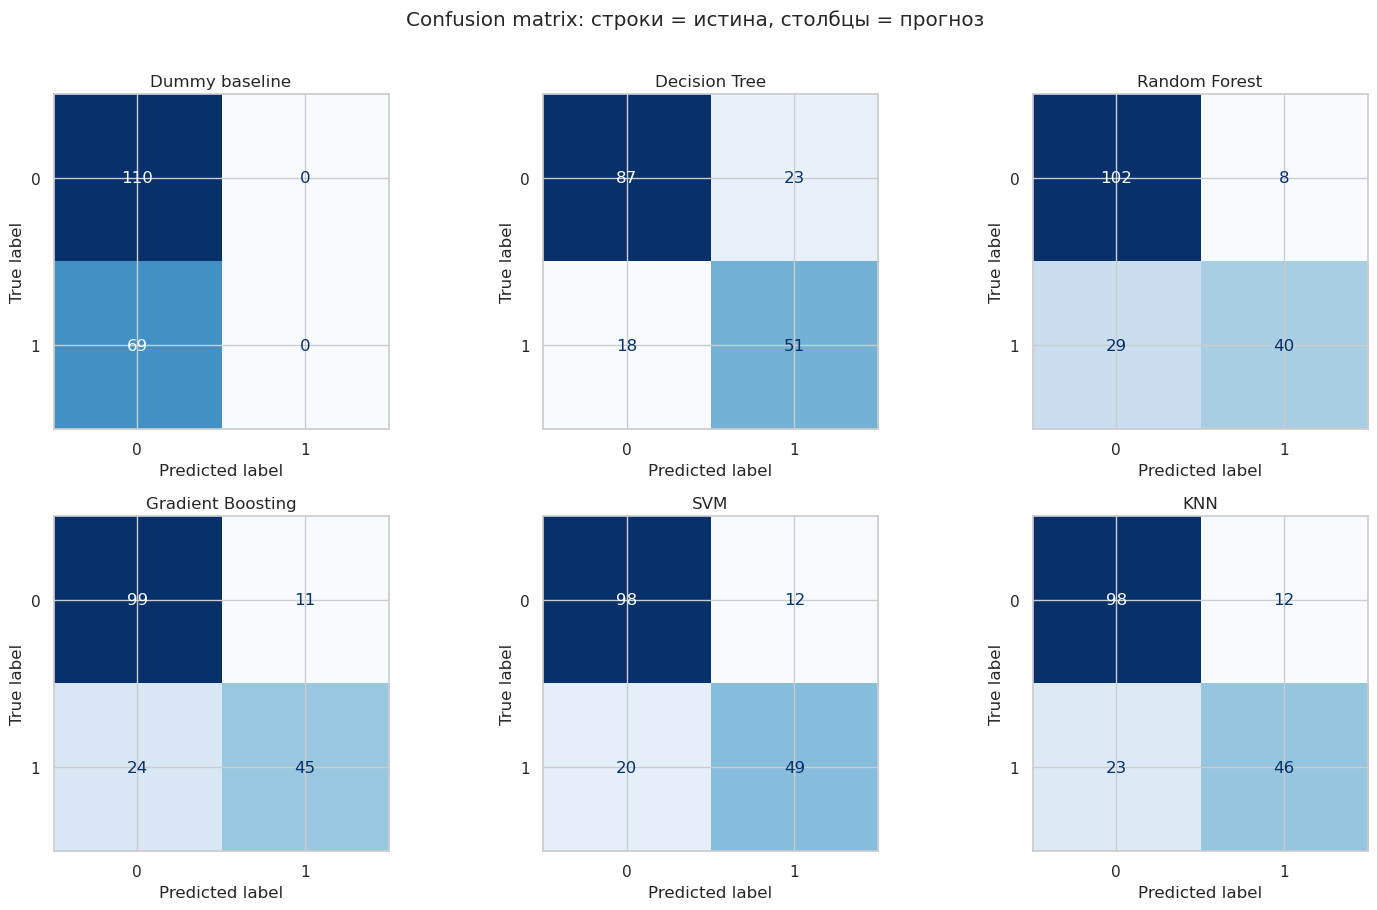

FP: модель предсказала выживание (1), но пассажир погиб (0).
FN: модель предсказала гибель (0), но пассажир выжил (1).


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, preds) in zip(axes.flat, all_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, preds, labels=[0,1], ax=ax,
       colorbar=False, cmap='Blues', values_format='d')
    ax.set_title(name)
plt.suptitle('Confusion matrix: строки = истина, столбцы = прогноз', y=1.01)
plt.tight_layout(); plt.show()
print('FP: модель предсказала выживание (1), но пассажир погиб (0).')
print('FN: модель предсказала гибель (0), но пассажир выжил (1).')


## 5. Проверка переобучения дерева и важность признаков

Высокое качество на обучении при заметно более низком качестве на тесте — признак возможного переобучения. Важность `feature_importances_` показывает использование признаков моделью, **а не причинное влияние на выживание**; она также может быть смещена в пользу непрерывных признаков.

Decision Tree F1 train: 0.884
Decision Tree F1 test:  0.713
Разница train-test: 0.171

 Decision Tree — ТОП-7:


,importance
cat__Sex_female,0.397
num__Fare,0.218
num__Age,0.192
cat__Pclass_3,0.100
cat__Pclass_1,0.036
cat__Embarked_S,0.034
num__SibSp,0.011



 Random Forest — ТОП-7:


,importance
cat__Sex_male,0.298
cat__Sex_female,0.263
num__Fare,0.104
cat__Pclass_3,0.093
num__Age,0.081
cat__Pclass_1,0.064
num__SibSp,0.025



 Gradient Boosting — ТОП-7:


,importance
cat__Sex_female,0.380
num__Fare,0.200
num__Age,0.159
cat__Pclass_3,0.111
cat__Sex_male,0.060
cat__Pclass_1,0.034
num__SibSp,0.029


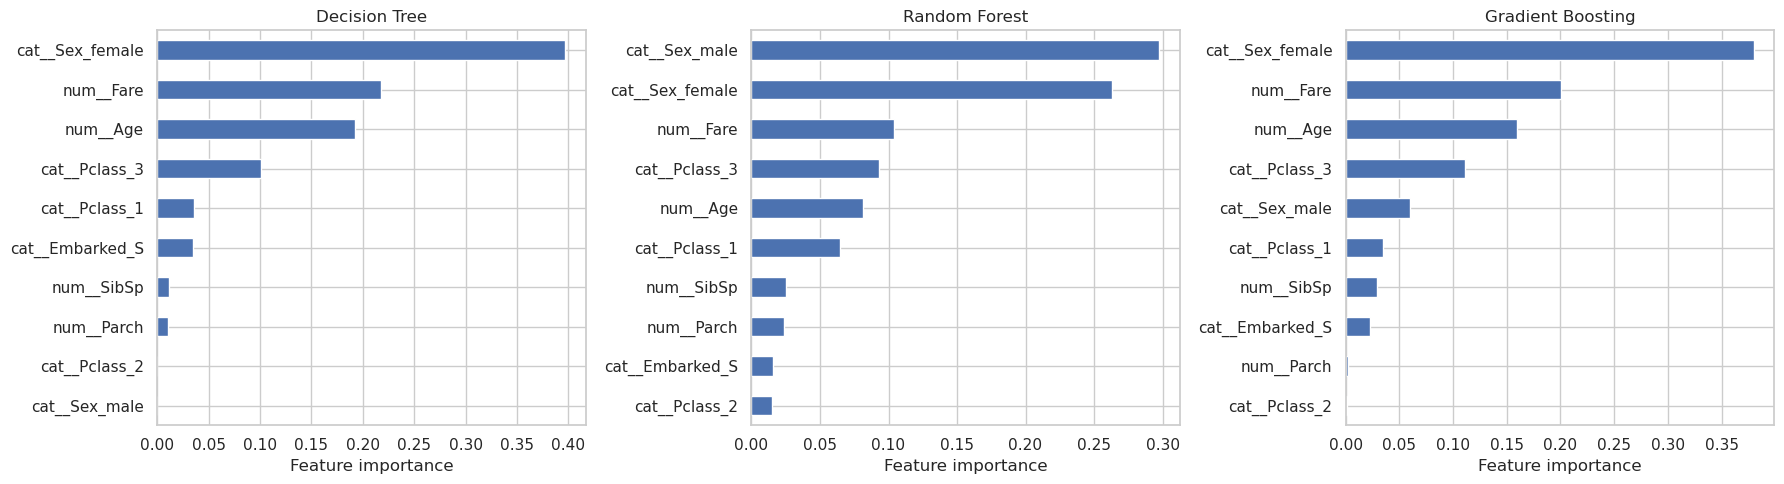

In [9]:
tree = models['Decision Tree']
print('Decision Tree F1 train:', round(f1_score(y_train, tree.predict(X_train)),3))
print('Decision Tree F1 test: ', round(f1_score(y_test, tree.predict(X_test)),3))
print('Разница train-test:', round(f1_score(y_train, tree.predict(X_train))-
                                f1_score(y_test, tree.predict(X_test)),3))

imp_frames=[]
for name in ['Decision Tree','Random Forest','Gradient Boosting']:
    pipe=models[name]
    names = pipe.named_steps['prep'].get_feature_names_out()
    importance = pipe.named_steps['model'].feature_importances_
    imp = pd.Series(importance, index=names).sort_values(ascending=False)
    print('\n',name, '— ТОП-7:')
    display(imp.head(7).round(3).rename('importance').to_frame())
    imp_frames.append(imp.rename(name))

importance_table = pd.concat(imp_frames, axis=1).fillna(0)
fig, axes = plt.subplots(1,3,figsize=(18,5))
for ax, name in zip(axes, ['Decision Tree','Random Forest','Gradient Boosting']):
    importance_table[name].sort_values().tail(10).plot.barh(ax=ax)
    ax.set_title(name); ax.set_xlabel('Feature importance')
plt.tight_layout();plt.show()


,Decision Tree,Random Forest,Gradient Boosting
Sex,0.397,0.561,0.440
Pclass,0.136,0.173,0.147
Fare,0.218,0.104,0.200
Age,0.192,0.081,0.159
Embarked,0.034,0.033,0.023
SibSp,0.011,0.025,0.029
Parch,0.010,0.023,0.002


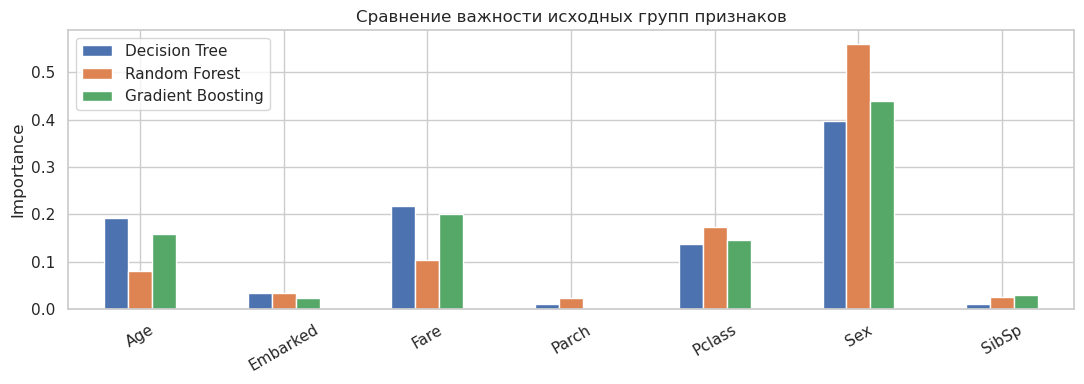

Сопоставьте сильнейшие признаки с EDA: Sex и Pclass отражают устойчивые различия в доле выживших.
Высокая importance НЕ доказывает, что изменение признака вызовет выживание: возможны корреляции и смешение факторов.


In [10]:
# Сравнение исходных групп признаков (суммируем one-hot категории).
base_features = ['Age','SibSp','Parch','Fare','Pclass','Sex','Embarked']
def original_group(transformed_name):
    tail = transformed_name.split('__',1)[-1]
    return next((col for col in base_features if tail == col or tail.startswith(col+'_')), tail)

importance_grouped = importance_table.groupby(
    [original_group(n) for n in importance_table.index]).sum()
display(importance_grouped.sort_values('Random Forest', ascending=False).round(3))
importance_grouped.plot(kind='bar', figsize=(11,4))
plt.title('Сравнение важности исходных групп признаков'); plt.ylabel('Importance')
plt.xticks(rotation=30); plt.tight_layout(); plt.show()
print('Сопоставьте сильнейшие признаки с EDA: Sex и Pclass отражают устойчивые различия в доле выживших.')
print('Высокая importance НЕ доказывает, что изменение признака вызовет выживание: возможны корреляции и смешение факторов.')


## 6. Анализ ошибок заранее выбранной по CV модели

Группы сравниваем по доле ошибок, **но небольшие группы дают нестабильные оценки**. Рассмотрим FP/FN и несколько ошибочно классифицированных пассажиров без использования ID или имени в обучении.

In [11]:
chosen = models[best_name]
pred = all_predictions[best_name]
errors = df.loc[X_test.index, ['PassengerId','Sex','Pclass','Age','Fare','Embarked','Survived']].copy()
errors['Predicted'] = pred
errors['Error'] = np.select([
    (errors.Survived==0)&(errors.Predicted==1),
    (errors.Survived==1)&(errors.Predicted==0)], ['FP','FN'], default='Correct')
print('Confusion matrix выбранной модели:')
display(pd.DataFrame(confusion_matrix(y_test,pred,labels=[0,1]),
                     index=['Actual 0','Actual 1'], columns=['Pred 0','Pred 1']))
print('Количество ошибок по типу:')
display(errors['Error'].value_counts().to_frame('count'))

for group in ['Sex','Pclass','Embarked']:
    print('\nОшибки по группе:', group)
    analysis = errors.groupby(group,dropna=False).agg(
        n=('Error','size'), error_rate=('Error', lambda s:(s!='Correct').mean()),
        FP=('Error',lambda s:(s=='FP').sum()), FN=('Error',lambda s:(s=='FN').sum()))
    display(analysis.sort_values('error_rate', ascending=False).round(3))

errors['Age_group'] = pd.cut(errors['Age'], [-np.inf,12,18,35,60,np.inf],
                            labels=['0–12','13–18','19–35','36–60','60+'])
print('\nОшибки по возрастным группам:')
display(errors.groupby('Age_group', observed=False).agg(
    n=('Error','size'), error_rate=('Error',lambda s:(s!='Correct').mean())).round(3))
print('\nПримеры неверных прогнозов (до 10):')
display(errors.loc[errors.Error!='Correct'].head(10))


Confusion matrix выбранной модели:


,Pred 0,Pred 1
Actual 0,99,11
Actual 1,24,45


Количество ошибок по типу:


,count
Error,
Correct,144
FN,24
FP,11



Ошибки по группе: Sex


...

,n,error_rate,FP,FN
Embarked,,,,
C,29,0.276,2,6
Q,22,0.182,4,0
S,128,0.180,5,18



Ошибки по возрастным группам:


,n,error_rate
Age_group,,
0–12,14,0.286
13–18,17,0.059
19–35,74,0.176
36–60,28,0.250
60+,6,0.167



Примеры неверных прогнозов (до 10):


,PassengerId,Sex,Pclass,Age,Fare,Embarked,Survived,Predicted,Error,Age_group
553,554,male,3,22.0,7.2250,C,1,0,FN,19–35
559,560,female,3,36.0,17.4000,S,1,0,FN,36–60
536,537,male,1,45.0,26.5500,S,0,1,FP,36–60
698,699,male,1,49.0,110.8833,C,0,1,FP,36–60
216,217,female,3,27.0,7.9250,S,1,0,FN,19–35
279,280,female,3,35.0,20.2500,S,1,0,FN,19–35
712,713,male,1,48.0,52.0000,S,1,0,FN,36–60
455,456,male,3,29.0,7.8958,C,1,0,FN,19–35
65,66,male,3,NaN,15.2458,C,1,0,FN,NaN
489,490,male,3,9.0,15.9000,S,1,0,FN,0–12


**Как интерпретировать ошибки:** для FP модель ошибочно ожидала выживание, для FN — ошибочно ожидала гибель. Даже при сходных возрасте, поле и классе конкретный исход мог зависеть от обстоятельств эвакуации, не представленных в данных. Самые высокие проценты ошибок в малых группах нельзя считать устойчивой закономерностью.

**Контроль возможной утечки:** `Survived` используется только как цель; `PassengerId`, `Name`, `Ticket`, `Cabin` не входят в признаки. Импутация, кодирование и масштабирование находятся внутри Pipeline и обучаются на train (а при CV — только на обучающих фолдах). `Fare`, `Pclass`, `Sex` и остальные используемые признаки известны до исхода события. При этом постановка с историческими данными может содержать другие смещения, поэтому результаты не следует считать причинными выводами.

## 7. Автоматический итог по фактическим результатам

In [12]:
passed=leaderboard.loc[leaderboard['F1 > 0.70'],'Модель'].tolist()
print(f'Порог F1 > 0.70 прошли: {", ".join(passed) if passed else "ни одна модель"}.')
print('Лучшая модель по 5-fold CV на train:', best_name,
      f'(CV F1={cv_f1[best_name]:.3f}; тест F1={f1_score(y_test, all_predictions[best_name]):.3f})')
print('Максимальный тестовый F1 (без перенастройки по тесту):',
      leaderboard.loc[0, 'Модель'], f'({leaderboard.loc[0,"F1"]:.3f})')
print('Возможные причины различий: деревья улавливают нелинейности и взаимодействия;',
      'ансамбли уменьшают нестабильность; SVM и KNN опираются на масштабированные расстояния;',
      'Dummy не учитывает признаки.')
print('Главные признаки по Random Forest:',
      ', '.join(importance_grouped['Random Forest'].nlargest(3).index.tolist()))

leaderboard.to_csv('lab02_leaderboard.csv', index=False)
errors.to_csv('lab02_errors.csv', index=False)
print('Экспортированы lab02_leaderboard.csv и lab02_errors.csv')


Порог F1 > 0.70 прошли: SVM, KNN, Gradient Boosting, Decision Tree.
Лучшая модель по 5-fold CV на train: Gradient Boosting (CV F1=0.767; тест F1=0.720)
Максимальный тестовый F1 (без перенастройки по тесту): SVM (0.754)
Возможные причины различий: деревья улавливают нелинейности и взаимодействия; ансамбли уменьшают нестабильность; SVM и KNN опираются на масштабированные расстояния; Dummy не учитывает признаки.
Главные признаки по Random Forest: Sex, Pclass, Fare
Экспортированы lab02_leaderboard.csv и lab02_errors.csv


### Заключение

По итогам выполнения сравните модели по **F1 на едином тесте**, а не только по Accuracy. Для решения, выбранного по train CV, приведите конкретные TP/TN/FP/FN и проблемные группы из таблиц выше. Помните, что важность признаков не является доказательством причинной связи. Качеством нельзя управлять повторным подбором по тесту: любые улучшения нужно оценивать внутри кросс-валидации на обучающей выборке.